In [1]:
# ---
# title: Evaluate Lit2Vec Subfield Classifier
# author: Bocklitz Lab
# date: 2025-08-21
# description: Evaluate Lit2Vec Subfield Classifier on test split and visualize results.
# ---

import os
import json
from pathlib import Path
from typing import List, Optional, Dict, Any
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# HF / data
from datasets import load_dataset, DatasetDict
from huggingface_hub import snapshot_download

# ML
import tensorflow as tf
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    roc_auc_score,
    average_precision_score,
    hamming_loss,
    label_ranking_average_precision_score,
    coverage_error,
    classification_report,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    auc,
    precision_recall_curve,
)

# YAML config
try:
    import yaml  # PyYAML
except ImportError as e:
    raise SystemExit("Missing dependency 'PyYAML'. Install with: pip install pyyaml") from e



/home/lit2vec-subfield-classifier/myenv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2025-08-26 15:12:39.549087: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2025-08-26 15:12:39.549142: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2025-08-26 15:12:39.550292: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


In [2]:

# ==============================
# Config loader
# ==============================
DEFAULT_CONFIG: Dict[str, Any] = {
    "model_repo_id": "Bocklitz-Lab/lit2vec-subfield-classifier-model",
    "dataset_id": "Bocklitz-Lab/lit2vec-subfield-classifier-dataset",
    "model_revision": "main",
    "dataset_revision": "main",
    "cache_dir": ".hf_cache_fresh",
    "save_dir": "eval_outputs",
    "model_file_candidates": ["mlp_model.h5", "model.h5", "keras_model.h5"],
    "label_mapping_file_candidates": ["label_mapping.json", "labels.json"],
    "embedding_field_candidates": ["embedding", "embeddings", "features", "x"],
    "label_field_candidates": ["labels", "label", "y", "targets"],
    "batch_size": 256,
    "threshold": 0.5,
    "random_seed": 42,
    "force_redownload": True,
    "use_token": True,
    "make_plots": True,
}

def load_config(path: str = "../configs/eval.yaml") -> Dict[str, Any]:
    with open(path, "r") as f:
        user_cfg = yaml.safe_load(f) or {}
    cfg = {**DEFAULT_CONFIG, **user_cfg}  # shallow merge
    # Normalize some fields
    for k in ["model_file_candidates", "label_mapping_file_candidates",
              "embedding_field_candidates", "label_field_candidates"]:
        if isinstance(cfg.get(k), str):
            cfg[k] = [cfg[k]]
    return cfg



In [3]:

# ==============================
# Helpers
# ==============================
def _find_field(column_names: List[str], candidates: List[str]) -> str:
    for name in candidates:
        if name in column_names:
            return name
    raise KeyError(f"None of the expected fields found. Tried: {candidates}. Available: {column_names}")

def _load_label_names_from_ds_features(test_ds) -> Optional[List[str]]:
    try:
        feat = test_ds.features.get("labels") or test_ds.features.get("label")
        # Multilabel often Sequence(ClassLabel)
        if hasattr(feat, "feature") and hasattr(feat.feature, "names"):
            return list(feat.feature.names)
        if hasattr(feat, "names"):
            return list(feat.names)
    except Exception:
        pass
    return None

def _load_label_mapping_from_repo(model_dir: str, candidates: List[str]) -> Optional[List[str]]:
    for fname in candidates:
        p = Path(model_dir) / fname
        if p.exists():
            with open(p, "r") as f:
                m = json.load(f)
            if isinstance(m, dict):
                if "label_to_index" in m and isinstance(m["label_to_index"], dict):
                    inv = sorted(m["label_to_index"].items(), key=lambda kv: kv[1])
                    return [k for k, _ in inv]
                # generic dict name->id
                if all(isinstance(v, int) for v in m.values()):
                    inv = sorted(m.items(), key=lambda kv: kv[1])
                    return [k for k, _ in inv]
                if "labels" in m and isinstance(m["labels"], list):
                    return list(m["labels"])
            if isinstance(m, list):
                return m
    return None

def _ensure_2d(arr_or_list) -> np.ndarray:
    X = np.asarray(arr_or_list, dtype=np.float32)
    if X.ndim == 1:
        X = X.reshape(-1, 1)
    return X

def _binarize_labels(raw_labels, num_classes: Optional[int], label_names: Optional[List[str]]):
    # Normalize to list of lists
    if len(raw_labels) == 0:
        raise ValueError("No labels in dataset.")
    if not isinstance(raw_labels[0], (list, tuple, np.ndarray)):
        raw_labels = [[x] for x in raw_labels]

    if isinstance(raw_labels[0][0], str):
        uniq = sorted({lbl for row in raw_labels for lbl in row})
        mlb = MultiLabelBinarizer(classes=uniq)
        Y = mlb.fit_transform(raw_labels).astype(int)
        names = list(mlb.classes_)
        return Y, names

    max_idx = max((int(x) for row in raw_labels for x in row), default=-1)
    C = max_idx + 1 if num_classes is None else num_classes
    mlb = MultiLabelBinarizer(classes=list(range(C)))
    Y = mlb.fit_transform(raw_labels).astype(int)
    names = label_names if label_names is not None else [f"Label {i}" for i in range(C)]
    return Y, names

def _safe_load_keras_model(model_dir: str, candidates: List[str]) -> tf.keras.Model:
    for fname in candidates:
        p = Path(model_dir) / fname
        if p.exists():
            return tf.keras.models.load_model(p, compile=False)
    h5s = list(Path(model_dir).glob("*.h5"))
    if not h5s:
        raise FileNotFoundError(f"No Keras .h5 model found in {model_dir}. Tried {candidates}")
    return tf.keras.models.load_model(h5s[0], compile=False)

def _save_fig(figpath: Path):
    plt.tight_layout()
    plt.savefig(figpath.with_suffix(".png"))
    plt.savefig(figpath.with_suffix(".pdf"))
    plt.show()



⬇️  Downloading dataset from Hugging Face…


Generating test split: 100%|██████████| 3990/3990 [00:00<00:00, 23524.32 examples/s]


Dataset({
    features: ['corpus_id', 'doi', 'url', 'title', 'authors', 'author_ids', 'venue', 'year', 'fields_of_study', 'publication_date', 'journal_name', 'license_publisher', 'license', 'oa_url', 'text', 'field_classification', 'text_type', 'embedding', 'label'],
    num_rows: 3990
})
⬇️  Downloading model repository…


Fetching 8 files: 100%|██████████| 8/8 [00:00<00:00, 79701.74it/s]


✅ X_test: (3990, 1024), Y_test: (3990, 18), classes: 18
🧠 Loading Keras model…
🔮 Running predictions…
16/16 [==============================] - 0s 3ms/step

📊 Computing metrics…

✅ === GLOBAL METRICS ===
Subset Accuracy        : 0.5083
Micro Precision        : 0.8541
Micro Recall           : 0.7662
Micro F1               : 0.8078
Macro Precision        : 0.8042
Macro Recall           : 0.7111
Macro F1               : 0.7476
Micro ROC AUC          : 0.9844
Macro ROC AUC          : 0.9778
Micro PR AUC           : 0.9014
Macro PR AUC           : 0.8425
Hamming Loss           : 0.0380
Label Ranking AP       : 0.9203
Coverage Error         : 2.4125

✅ === PER-LABEL CLASSIFICATION REPORT ===
                                    precision    recall  f1-score   support

                         Catalysis       0.83      0.78      0.80       197
                 Organic Chemistry       0.85      0.60      0.70       245
                 Polymer Chemistry       0.80      0.65      0.72       120
 

/tmp/ipykernel_48204/2391099551.py:193: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y="Label", x="Support", data=tmp, palette="crest")


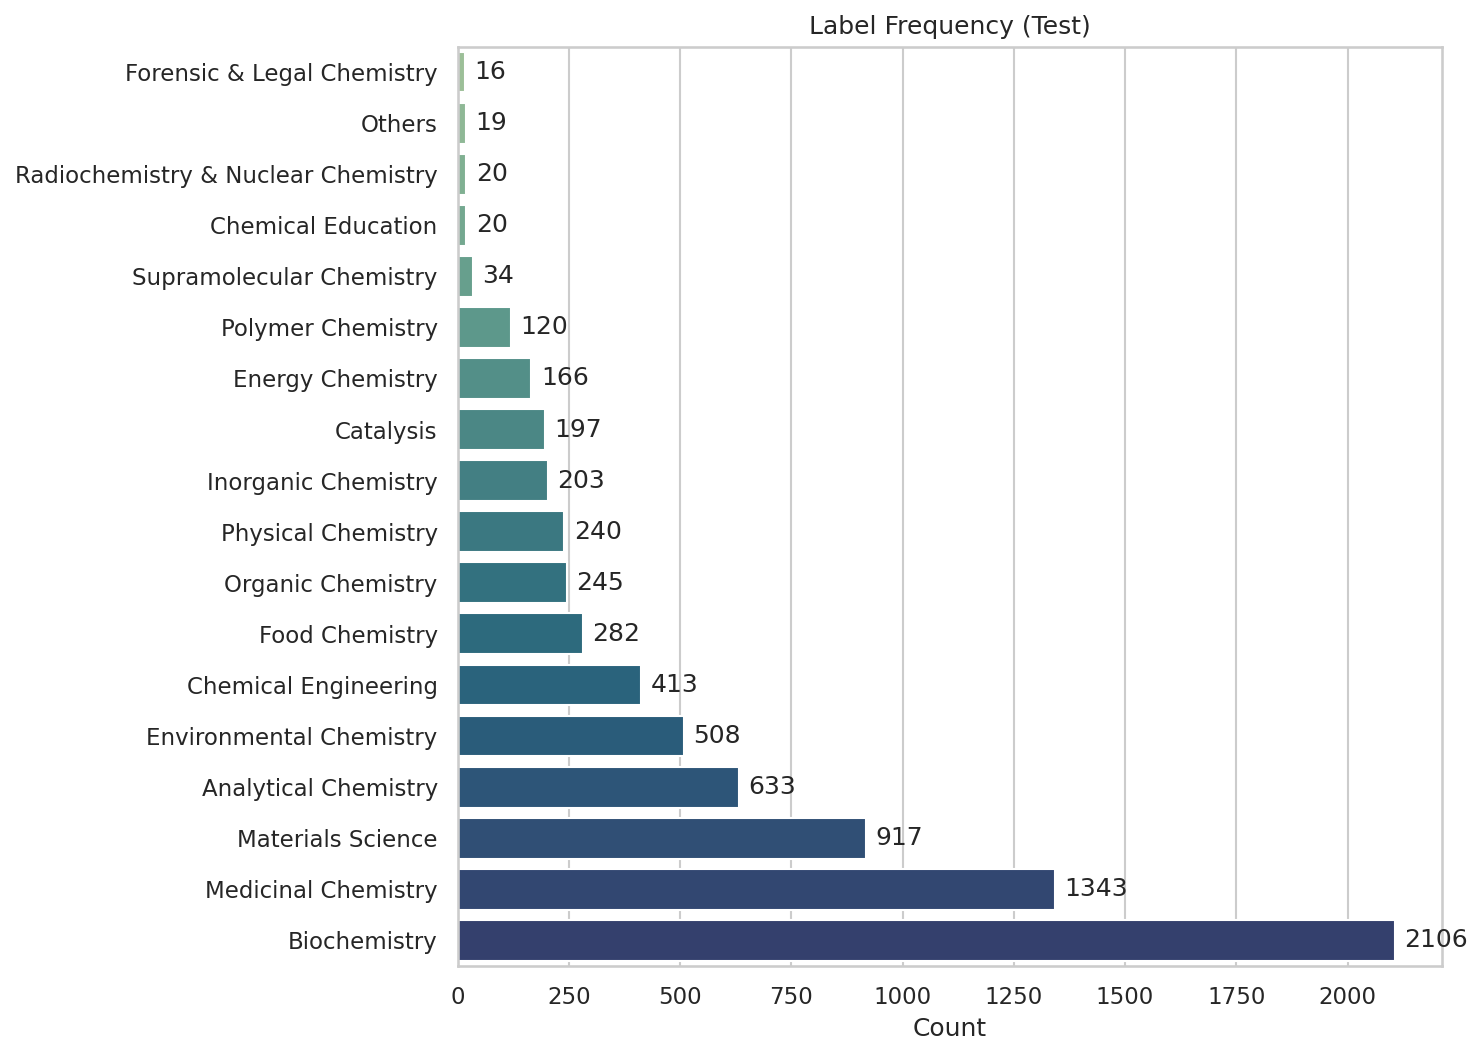

/tmp/ipykernel_48204/2391099551.py:203: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y="Label", x="F1", data=tmp2, palette="YlGn")


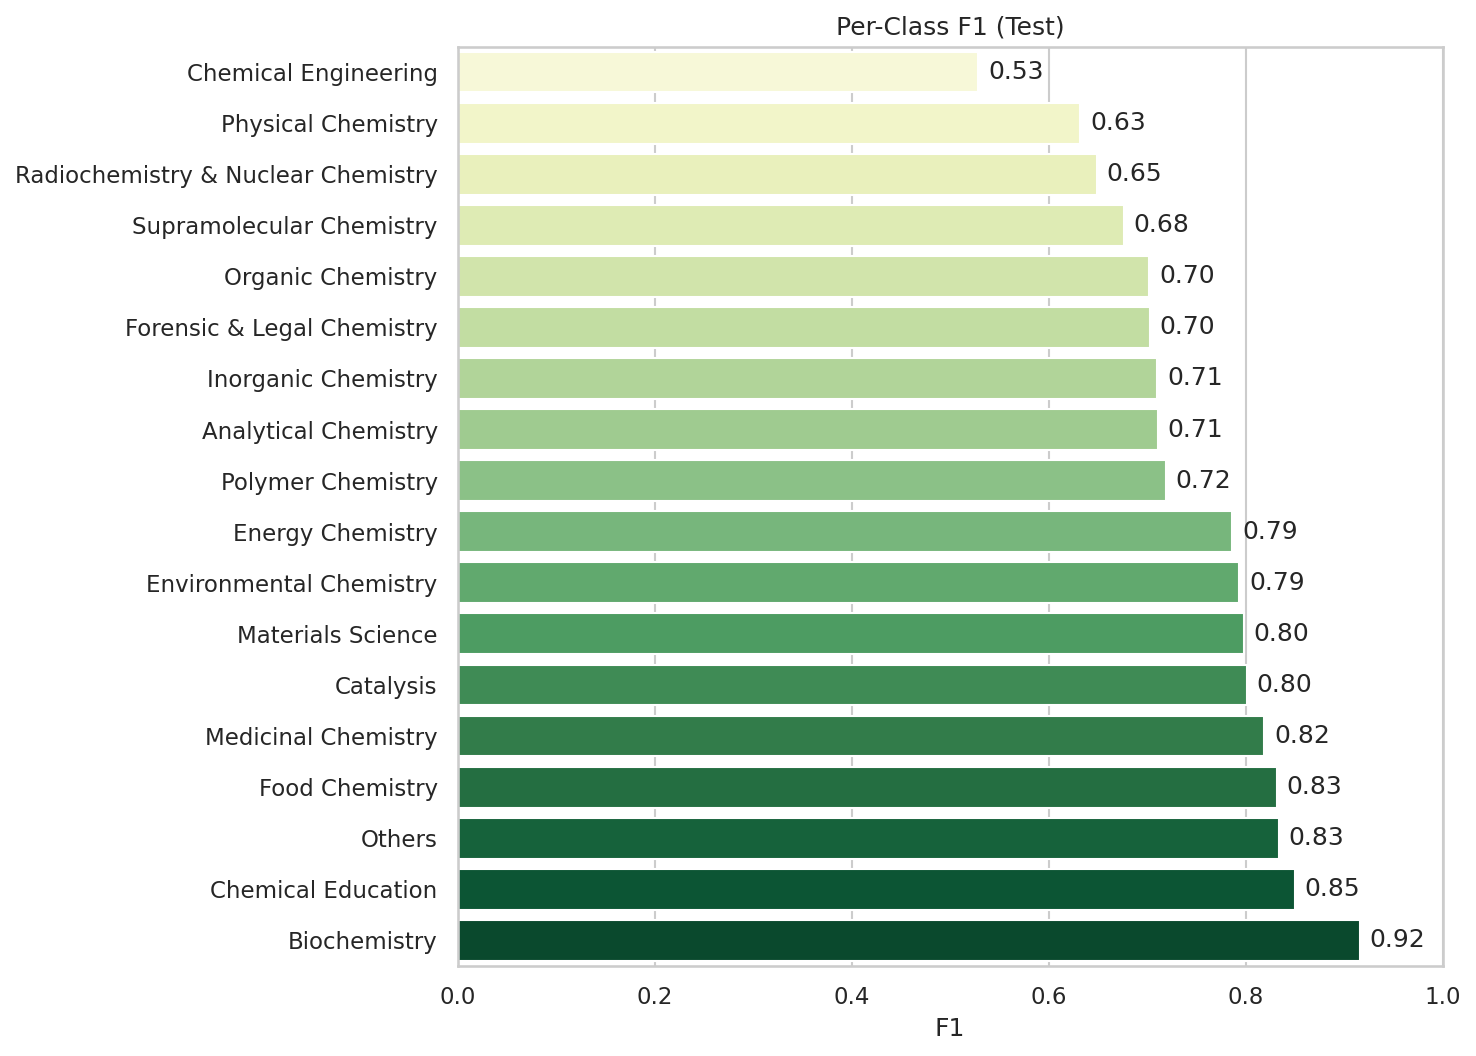

<Figure size 750x600 with 0 Axes>

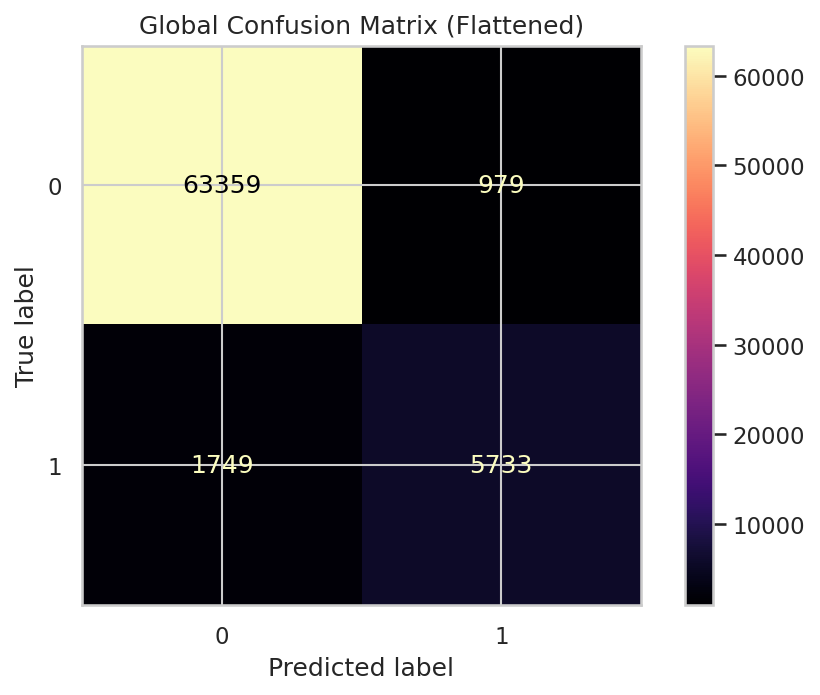

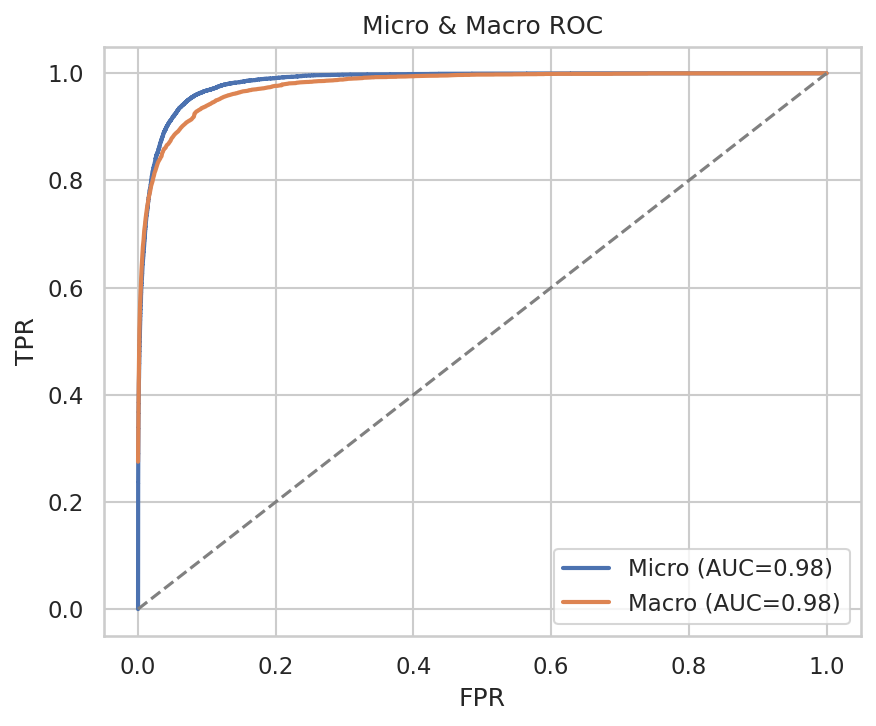

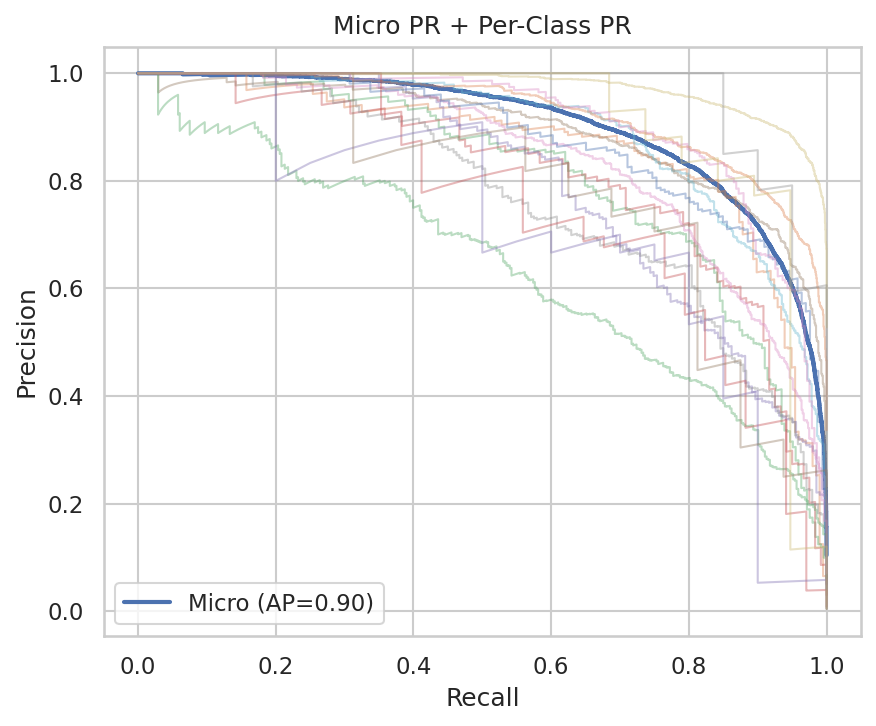

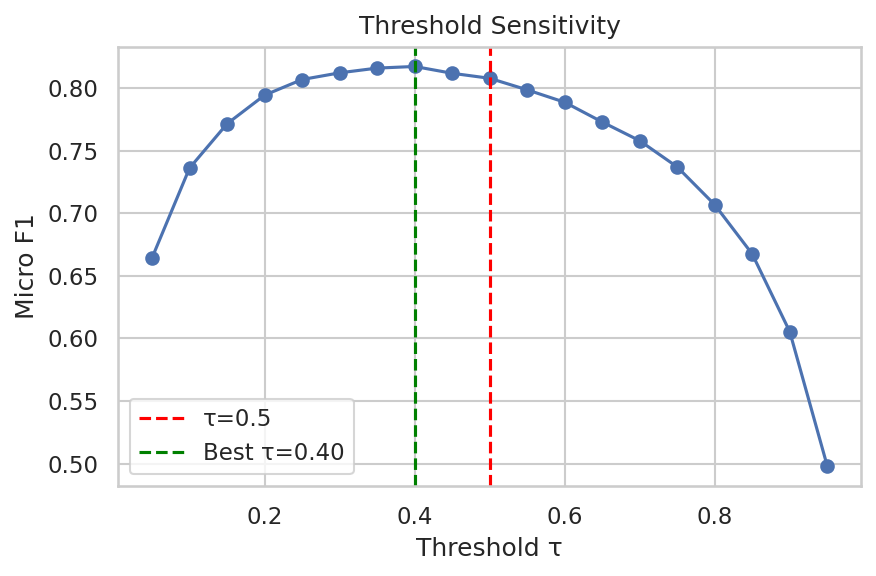

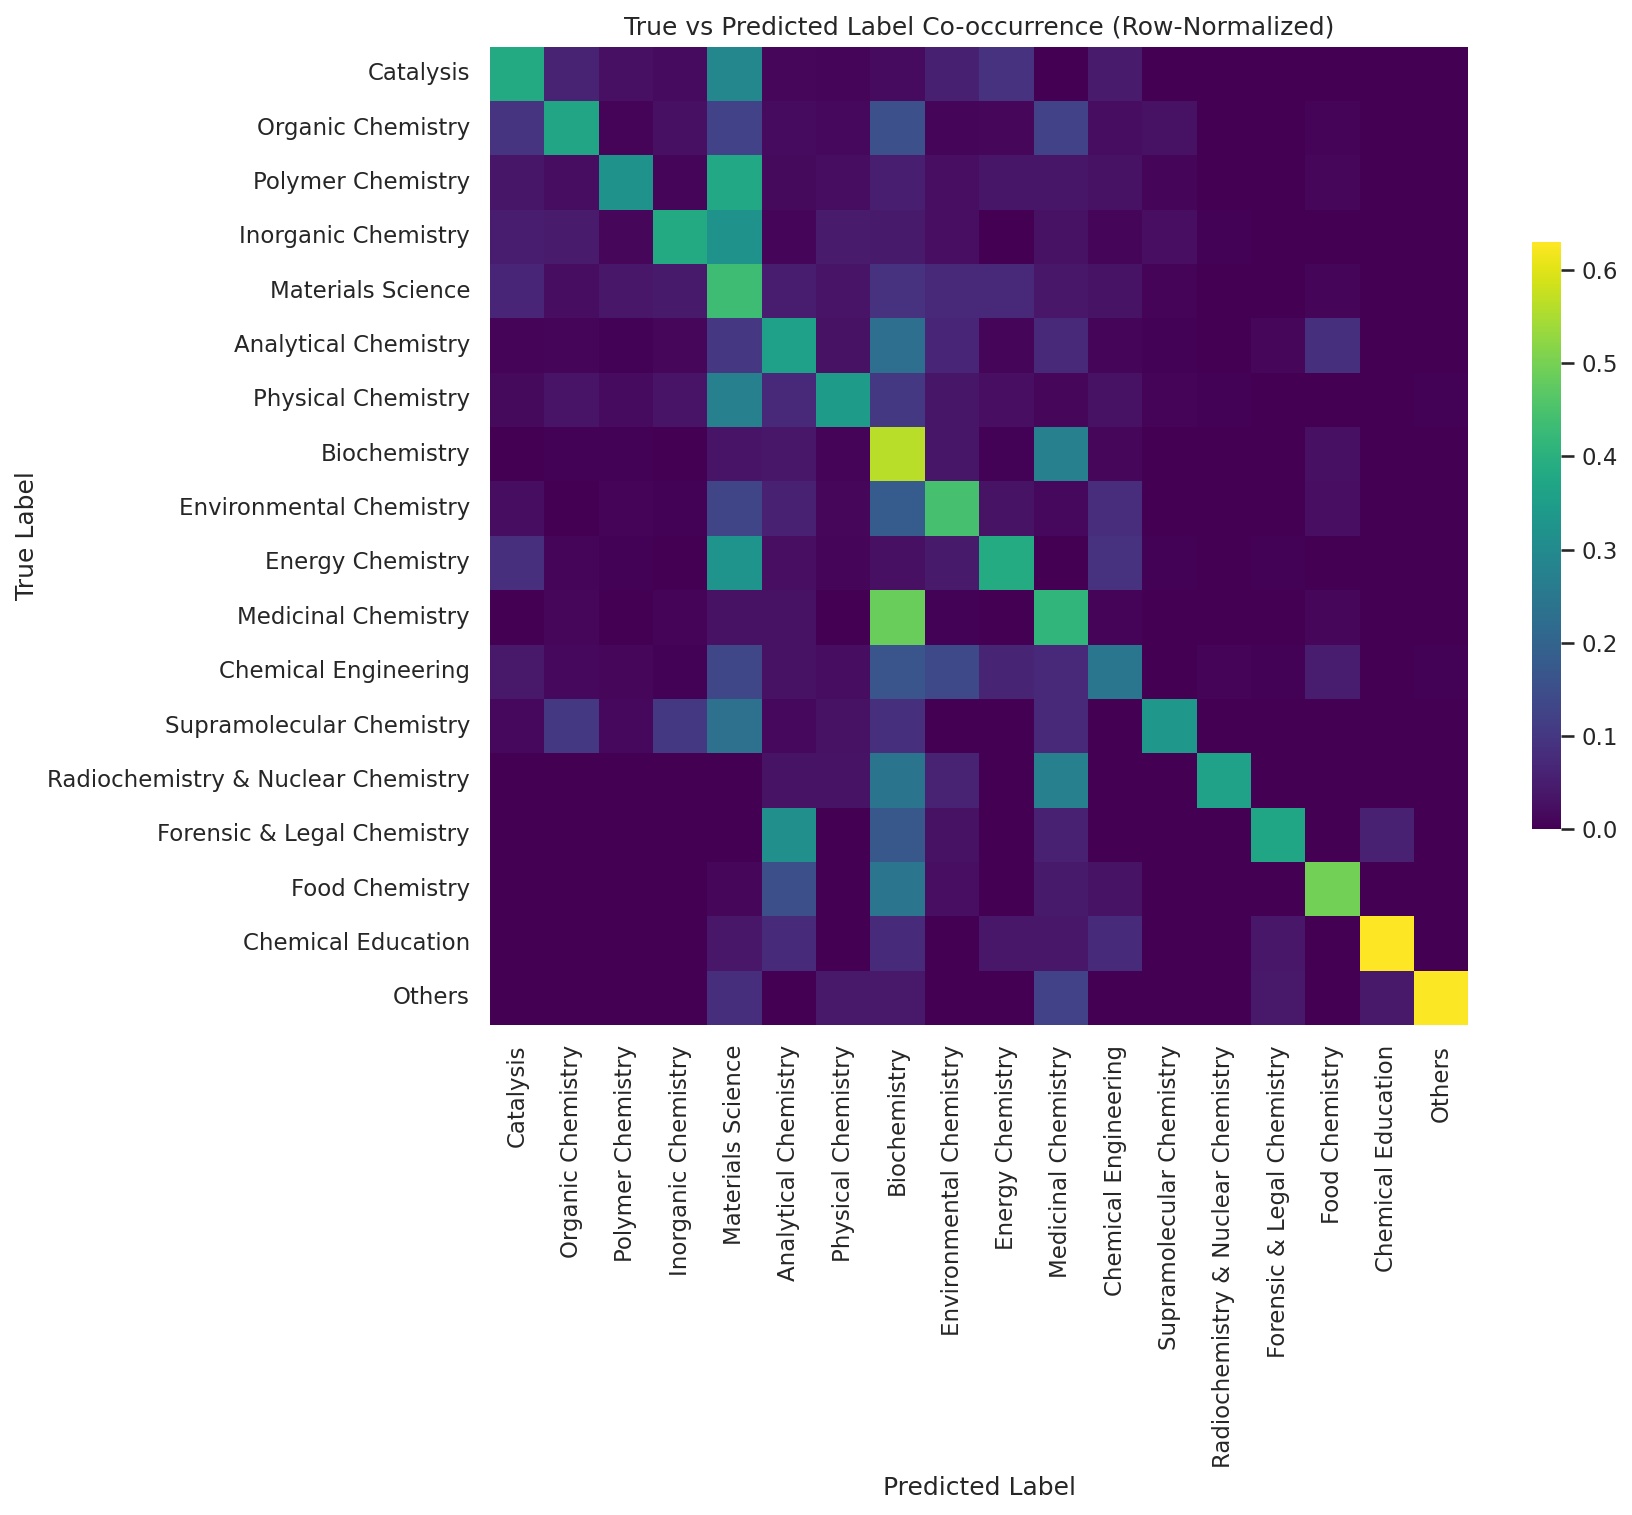

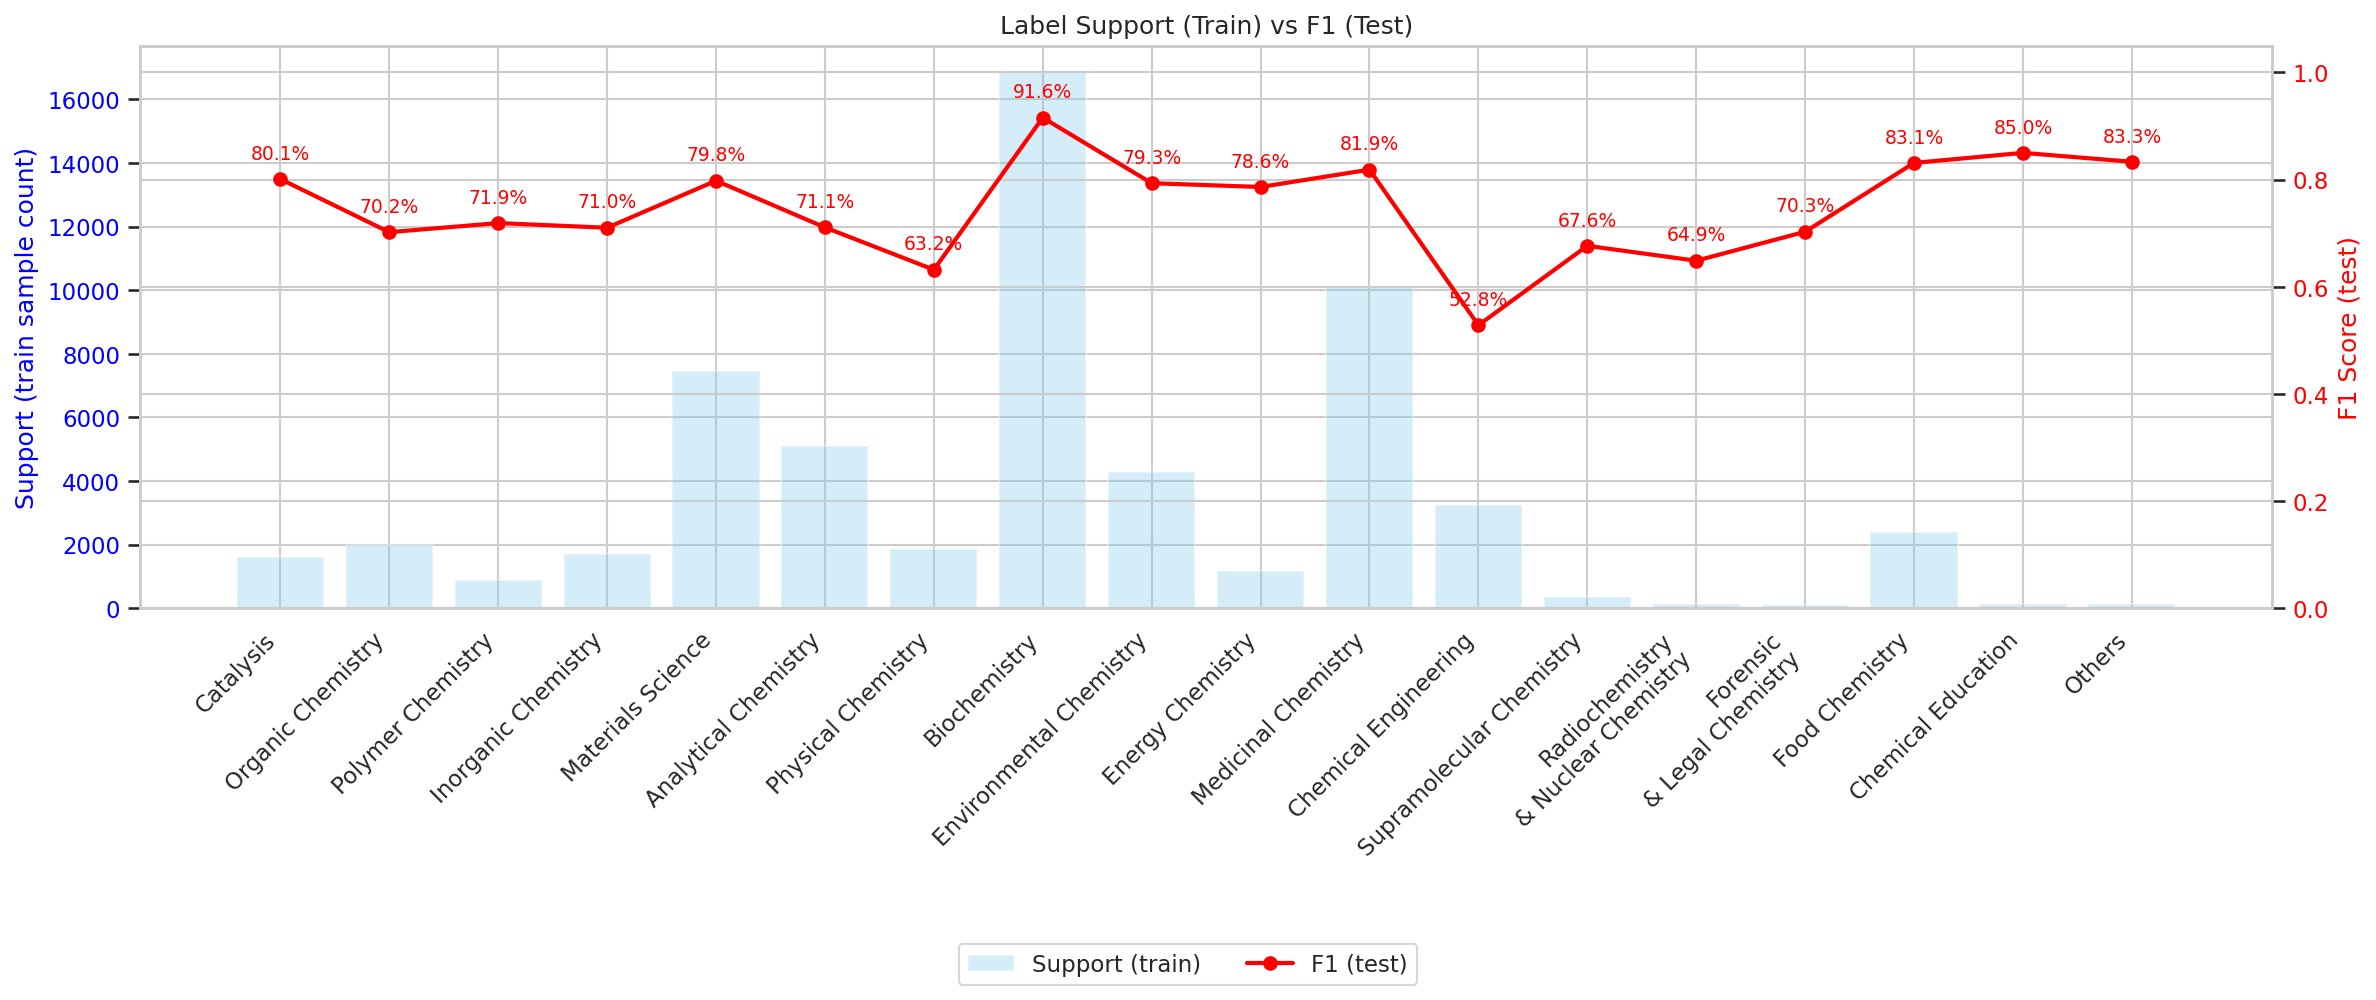


🎉 Done! Artifacts saved to: /home/lit2vec-subfield-classifier/notebooks/eval_outputs


In [8]:

# ==============================
# Main
# ==============================
def main():
    cfg = load_config("../configs/eval.yaml")

    sns.set(style="whitegrid")
    plt.rcParams.update({
        "figure.dpi": 150,
        "savefig.dpi": 300,
        "pdf.fonttype": 42, "ps.fonttype": 42
    })

    SAVE_DIR = Path(cfg["save_dir"])
    SAVE_DIR.mkdir(parents=True, exist_ok=True)

    # 1) Download dataset
    print("⬇️  Downloading dataset from Hugging Face…")
    download_mode = "force_redownload" if cfg.get("force_redownload", True) else "reuse_dataset_if_exists"
    try:
        ds: DatasetDict = load_dataset(
            cfg["dataset_id"],
            split=None,
            token=cfg.get("use_token", True),
            revision=cfg["dataset_revision"],
            cache_dir=cfg["cache_dir"],
            download_mode=download_mode,
        )
    except TypeError:
        ds = load_dataset(
            cfg["dataset_id"],
            split=None,
            use_auth_token=cfg.get("use_token", True),
            revision=cfg["dataset_revision"],
            cache_dir=cfg["cache_dir"],
            download_mode=download_mode,
        )

    if "test" not in ds:
        raise ValueError(f"Dataset {cfg['dataset_id']} must provide a 'test' split. Available: {list(ds.keys())}")

    test_ds = ds["test"]
    print(test_ds)

    # 2) Download model repo
    print("⬇️  Downloading model repository…")
    model_dir = snapshot_download(
        repo_id=cfg["model_repo_id"],
        revision=cfg["model_revision"],
        cache_dir=cfg["cache_dir"],
        local_dir=None,
        local_dir_use_symlinks=True,
    )

    # 3) Prepare X_test, Y_test, label names
    emb_field = _find_field(test_ds.column_names, cfg["embedding_field_candidates"])
    lab_field = _find_field(test_ds.column_names, cfg["label_field_candidates"])

    X_list = test_ds[emb_field]   # list[list[float]]
    raw_labels = test_ds[lab_field]

    X_test = _ensure_2d(X_list)

    # Try names from repo, then dataset features
    label_names_from_repo = _load_label_mapping_from_repo(model_dir, cfg["label_mapping_file_candidates"])
    label_names_from_ds    = _load_label_names_from_ds_features(test_ds)
    label_names = label_names_from_repo or label_names_from_ds

    num_classes_hint = len(label_names) if label_names is not None else None
    Y_test, label_names = _binarize_labels(raw_labels, num_classes=num_classes_hint, label_names=label_names)

    assert X_test.shape[0] == Y_test.shape[0], "Embedding/label sample count mismatch."

    np.save(SAVE_DIR / "X_test.npy", X_test)
    np.save(SAVE_DIR / "Y_test.npy", Y_test)
    with open(SAVE_DIR / "label_names.json", "w") as f:
        json.dump(label_names, f)

    print(f"✅ X_test: {X_test.shape}, Y_test: {Y_test.shape}, classes: {len(label_names)}")

    # 4) Load model & predict
    print("🧠 Loading Keras model…")
    model = _safe_load_keras_model(model_dir, cfg["model_file_candidates"])

    print("🔮 Running predictions…")
    y_probs = model.predict(X_test, batch_size=int(cfg["batch_size"]), verbose=1)
    y_probs = np.asarray(y_probs, dtype=np.float32)
    y_pred  = (y_probs >= float(cfg["threshold"])).astype(int)

    np.save(SAVE_DIR / "y_pred_probs.npy", y_probs)
    np.save(SAVE_DIR / "y_pred.npy", y_pred)

    # 5) Metrics
    print("\n📊 Computing metrics…")
    subset_acc = accuracy_score(Y_test, y_pred)

    micro_p, micro_r, micro_f1, _ = precision_recall_fscore_support(
        Y_test, y_pred, average="micro", zero_division=0)
    macro_p, macro_r, macro_f1, _ = precision_recall_fscore_support(
        Y_test, y_pred, average="macro", zero_division=0)

    try:
        micro_roc_auc = roc_auc_score(Y_test, y_probs, average="micro")
        macro_roc_auc = roc_auc_score(Y_test, y_probs, average="macro")
    except ValueError:
        micro_roc_auc = None
        macro_roc_auc = None

    micro_pr_auc = average_precision_score(Y_test, y_probs, average="micro")
    macro_pr_auc = average_precision_score(Y_test, y_probs, average="macro")
    ham_loss = hamming_loss(Y_test, y_pred)
    lrap = label_ranking_average_precision_score(Y_test, y_probs)
    cov_err = coverage_error(Y_test, y_probs)

    per_label = precision_recall_fscore_support(
        Y_test, y_pred, average=None, zero_division=0)
    per_label_dict = {
        lbl: {"precision": float(p), "recall": float(r), "f1": float(f), "support": int(s)}
        for lbl, p, r, f, s in zip(label_names, *per_label)
    }

    print("\n✅ === GLOBAL METRICS ===")
    print(f"Subset Accuracy        : {subset_acc:.4f}")
    print(f"Micro Precision        : {micro_p:.4f}")
    print(f"Micro Recall           : {micro_r:.4f}")
    print(f"Micro F1               : {micro_f1:.4f}")
    print(f"Macro Precision        : {macro_p:.4f}")
    print(f"Macro Recall           : {macro_r:.4f}")
    print(f"Macro F1               : {macro_f1:.4f}")
    print(f"Micro ROC AUC          : {micro_roc_auc:.4f}" if micro_roc_auc is not None else "Micro ROC AUC          : N/A")
    print(f"Macro ROC AUC          : {macro_roc_auc:.4f}" if macro_roc_auc is not None else "Macro ROC AUC          : N/A")
    print(f"Micro PR AUC           : {micro_pr_auc:.4f}")
    print(f"Macro PR AUC           : {macro_pr_auc:.4f}")
    print(f"Hamming Loss           : {ham_loss:.4f}")
    print(f"Label Ranking AP       : {lrap:.4f}")
    print(f"Coverage Error         : {cov_err:.4f}")

    with open(SAVE_DIR / "metrics_summary.json", "w") as f:
        json.dump({
            "subset_accuracy": subset_acc,
            "micro_precision": micro_p,
            "micro_recall": micro_r,
            "micro_f1": micro_f1,
            "macro_precision": macro_p,
            "macro_recall": macro_r,
            "macro_f1": macro_f1,
            "micro_roc_auc": micro_roc_auc,
            "macro_roc_auc": macro_roc_auc,
            "micro_pr_auc": micro_pr_auc,
            "macro_pr_auc": macro_pr_auc,
            "hamming_loss": ham_loss,
            "label_ranking_average_precision": lrap,
            "coverage_error": cov_err,
            "per_label": per_label_dict,
            "threshold": float(cfg["threshold"]),
        }, f, indent=2)

    print("\n✅ === PER-LABEL CLASSIFICATION REPORT ===")
    print(classification_report(Y_test, y_pred, target_names=label_names, zero_division=0))

    # Classification report CSV + LaTeX preview
    report = classification_report(Y_test, y_pred, target_names=label_names, output_dict=True, zero_division=0)
    report_df = pd.DataFrame(report).transpose()
    report_df.to_csv(SAVE_DIR / "final_classification_report.csv")
    print("\n✅ LaTeX preview:")
    print(report_df.round(3).to_latex(index=True))

    # --- compute train support counts ---
    if "train" in ds:
        train_raw_labels = ds["train"][lab_field]
        Y_train_for_counts, _ = _binarize_labels(
            train_raw_labels,
            num_classes=len(label_names),
            label_names=label_names
        )
        train_label_counts = Y_train_for_counts.sum(axis=0)
    else:
        print("ℹ️ No 'train' split found; using test counts for support bars.")
        train_label_counts = Y_test.sum(axis=0)

    # (optional: save for reproducibility)
    np.save(SAVE_DIR / "train_label_counts.npy", train_label_counts)



    # 6) Visualizations (optional)
    if cfg.get("make_plots", True):
        # Label frequency
        label_counts = Y_test.sum(axis=0)
        tmp = pd.DataFrame({"Label": label_names, "Support": label_counts.astype(int)})
        tmp = tmp.sort_values("Support", ascending=True)
        plt.figure(figsize=(10, max(6, len(label_names) * 0.4)))
        sns.barplot(y="Label", x="Support", data=tmp, palette="crest")
        for i, v in enumerate(tmp["Support"].values):
            plt.text(v + max(label_counts)*0.01, i, str(int(v)), va="center")
        plt.title("Label Frequency (Test)"); plt.xlabel("Count"); plt.ylabel("")
        _save_fig(SAVE_DIR / "label_frequency")

        # Per-class F1
        f1s = [per_label_dict[lbl]["f1"] for lbl in label_names]
        tmp2 = pd.DataFrame({"Label": label_names, "F1": f1s}).sort_values("F1", ascending=True)
        plt.figure(figsize=(10, max(6, len(label_names) * 0.4)))
        sns.barplot(y="Label", x="F1", data=tmp2, palette="YlGn")
        for i, v in enumerate(tmp2["F1"].values):
            plt.text(min(0.98, v + 0.01), i, f"{v:.2f}", va="center")
        plt.xlim(0, 1); plt.title("Per-Class F1 (Test)"); plt.xlabel("F1"); plt.ylabel("")
        _save_fig(SAVE_DIR / "f1_barplot")

        # Global confusion matrix (flattened)
        y_true_flat = Y_test.ravel()
        y_pred_flat = y_pred.ravel()
        global_cm = confusion_matrix(y_true_flat, y_pred_flat)
        plt.figure(figsize=(5, 4))
        disp = ConfusionMatrixDisplay(confusion_matrix=global_cm, display_labels=["0","1"])
        disp.plot(cmap="magma", values_format='d')
        plt.title("Global Confusion Matrix (Flattened)")
        _save_fig(SAVE_DIR / "global_confusion_matrix")

        # ROC micro/macro
        fpr, tpr, roc_auc = {}, {}, {}
        for i in range(len(label_names)):
            fpr[i], tpr[i], _ = roc_curve(Y_test[:, i], y_probs[:, i])
            roc_auc[i] = auc(fpr[i], tpr[i])
        fpr["micro"], tpr["micro"], _ = roc_curve(Y_test.ravel(), y_probs.ravel())
        roc_auc["micro"] = auc(fpr["micro"], tpr["micro"])
        macro_fpr = np.linspace(0, 1, 1000)
        tprs = [np.interp(macro_fpr, fpr[i], tpr[i]) for i in range(len(label_names))]
        macro_tpr = np.mean(tprs, axis=0)
        roc_auc["macro"] = auc(macro_fpr, macro_tpr)
        plt.figure(figsize=(6,5))
        plt.plot(fpr["micro"], tpr["micro"], label=f"Micro (AUC={roc_auc['micro']:.2f})", lw=2)
        plt.plot(macro_fpr, macro_tpr, label=f"Macro (AUC={roc_auc['macro']:.2f})", lw=2)
        plt.plot([0,1],[0,1],'--',color='grey')
        plt.xlabel("FPR"); plt.ylabel("TPR"); plt.title("Micro & Macro ROC"); plt.legend()
        _save_fig(SAVE_DIR / "roc_micro_macro")

        # PR micro (+ faint per-class)
        precision_d, recall_d, pr_auc_d = {}, {}, {}
        precision_d["micro"], recall_d["micro"], _ = precision_recall_curve(Y_test.ravel(), y_probs.ravel())
        pr_auc_d["micro"] = average_precision_score(Y_test, y_probs, average="micro")
        plt.figure(figsize=(6,5))
        plt.plot(recall_d["micro"], precision_d["micro"], label=f"Micro (AP={pr_auc_d['micro']:.2f})", lw=2)
        for i in range(len(label_names)):
            pi, ri, _ = precision_recall_curve(Y_test[:, i], y_probs[:, i])
            plt.plot(ri, pi, lw=1, alpha=0.4)
        plt.xlabel("Recall"); plt.ylabel("Precision"); plt.title("Micro PR + Per-Class PR"); plt.legend()
        _save_fig(SAVE_DIR / "pr_micro")

        # Threshold sweep (micro-F1)
        thresholds = np.linspace(0.05, 0.95, 19)
        micro_f1s = []
        for t in thresholds:
            preds = (y_probs >= t).astype(int)
            micro_f1s.append(f1_score(Y_test, preds, average="micro"))
        best_t = float(thresholds[int(np.argmax(micro_f1s))])
        plt.figure(figsize=(6,4))
        plt.plot(thresholds, micro_f1s, marker='o')
        plt.axvline(float(cfg["threshold"]), ls='--', color='red', label=f'τ={cfg["threshold"]}')
        plt.axvline(best_t, ls='--', color='green', label=f'Best τ={best_t:.2f}')
        plt.xlabel("Threshold τ"); plt.ylabel("Micro F1"); plt.title("Threshold Sensitivity"); plt.legend()
        _save_fig(SAVE_DIR / "threshold_sweep")


        # ==============================
        # True vs Predicted Co-occurrence (row-normalized)
        # ==============================
        num_labels = Y_test.shape[1]
        co_matrix = np.zeros((num_labels, num_labels), dtype=np.int32)

        for i in range(len(Y_test)):
            true_labels = np.where(Y_test[i] == 1)[0]
            pred_labels = np.where(y_pred[i] == 1)[0]
            for t in true_labels:
                for p in pred_labels:
                    co_matrix[t, p] += 1

        co_matrix_norm = co_matrix / (co_matrix.sum(axis=1, keepdims=True) + 1e-6)

        plt.figure(figsize=(12, 10))
        sns.heatmap(
            co_matrix_norm,
            xticklabels=label_names,
            yticklabels=label_names,
            cmap="viridis",
            square=True,
            annot=False,
            cbar_kws={"shrink": 0.6}
        )
        plt.xlabel("Predicted Label")
        plt.ylabel("True Label")
        plt.title("True vs Predicted Label Co-occurrence (Row-Normalized)")
        _save_fig(SAVE_DIR / "cooccurrence_true_vs_pred")

        # ==============================
        # Label Support (TRAIN) vs F1 (TEST) with % labels
        # ==============================
        supports = train_label_counts.astype(int)
        f1s = [per_label_dict[lbl]["f1"] for lbl in label_names]

        wrapped_labels = [lbl.replace(" & ", "\n& ") for lbl in label_names]
        x = list(range(len(label_names)))
        fig, ax1 = plt.subplots(figsize=(16, 6))

        # Bars: TRAIN support
        ax1.bar(x, supports, color='skyblue', alpha=0.35, label='Support (train)')
        ax1.set_ylabel("Support (train sample count)", color='blue')
        ax1.tick_params(axis='y', labelcolor='blue')

        # Line: TEST F1
        ax2 = ax1.twinx()
        ax2.plot(x, f1s, color='red', marker='o', linewidth=2, label='F1 (test)')
        ax2.set_ylabel("F1 Score (test)", color='red')
        ax2.tick_params(axis='y', labelcolor='red')
        ax2.set_ylim(0, 1.05)

        # Annotate F1 points with percentages
        for i, (x_pos, f1) in enumerate(zip(x, f1s)):
            ax2.text(
                x_pos, f1 + 0.03, f"{f1*100:.1f}%",  # percentage label
                ha='center', va='bottom', color='red', fontsize=9, rotation=0
            )

        ax1.set_xticks(x)
        ax1.set_xticklabels(wrapped_labels, rotation=45, ha='right')

        plt.title("Label Support (Train) vs F1 (Test)")
        fig.legend(loc='upper center', bbox_to_anchor=(0.5, -0.05), ncol=2)
        plt.tight_layout()
        _save_fig(SAVE_DIR / "support_train_vs_f1_test")


    print(f"\n🎉 Done! Artifacts saved to: {SAVE_DIR.resolve()}")

if __name__ == "__main__":
    main()
